# Sentiment Analysis using Sparse Representation (TF-IDF)

This notebook implements the complete end-to-end sentiment analysis pipeline on the IMDB dataset using **sparse representations**.

```
[ Raw Text ]
     ↓
[ Preprocessing & Cleaning ]
     ↓
[ TF-IDF Vectorization ] (Sparse Matrix)
     ↓
[ Train Classifiers (Logistic Regression, LinearSVC, Naive Bayes) ]
     ↓
[ Evaluation (F1-Score, Confusion Matrix, Classification Report) ]
     ↓
[ Feature Importance & Interpretability ]
     ↓
[ Hyperparameter Tuning (GridSearchCV) ]
     ↓
[ Inference on New Text & Model Persistence ]
```

## Stage 0: Imports & Environment Setup
Import all core data manipulation, visualization, text processing, and scikit-learn machine learning modules.

In [1]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
print("All libraries imported successfully!")

All libraries imported successfully!


## Stage 1: Load Raw Dataset & Train/Test Split
Load the IMDB dataset from `../data/raw/IMDB Dataset.csv`, encode binary sentiment labels (`positive -> 1`, `negative -> 0`), and perform a stratified train/test split.

In [2]:
data_path = os.path.join("..", "data", "raw", "IMDB Dataset.csv")

if os.path.exists(data_path):
    df = pd.read_csv(data_path)
    print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
else:
    # Fallback dummy sample if dataset path differs
    print(f"Warning: {data_path} not found. Creating a representative sample.")
    df = pd.DataFrame({
        "review": [
            "This movie was fantastic and brilliant!",
            "Terrible acting, boring story, absolute waste of time.",
            "A masterpiece of cinema with incredible cinematography.",
            "Horrible direction and awful script, hated every minute.",
            "Highly recommended, loved the plot and characters.",
            "Disappointing and dull. Not worth watching at all."
        ],
        "sentiment": ["positive", "negative", "positive", "negative", "positive", "negative"]
    })

# Map sentiment: positive -> 1, negative -> 0
df["label"] = df["sentiment"].map({"positive": 1, "negative": 0})

# Stratified Train / Test Split (80% train, 20% test)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df["review"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print(f"Training set size: {len(X_train_raw):,} samples")
print(f"Test set size:     {len(X_test_raw):,} samples")
print("Class distribution in train:", y_train.value_counts(normalize=True).to_dict())

Loaded dataset: 50,000 rows, 2 columns
Training set size: 40,000 samples
Test set size:     10,000 samples
Class distribution in train: {1: 0.5, 0: 0.5}


## Stage 2: Text Preprocessing & Cleaning
Clean the raw text before vectorization by removing HTML break tags (`<br />`), stripping special characters, and normalizing extra whitespace.

In [3]:
def clean_text(text: str) -> str:
    """Cleans raw review text for sparse vectorization."""
    # Remove HTML tags (e.g. <br />, <b>)
    text = re.sub(r"<.*?>", " ", str(text))
    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)
    # Normalize multiple whitespace
    text = re.sub(r"\s+", " ", text).strip()
    return text

print("Cleaning train and test reviews...")
X_train_clean = X_train_raw.apply(clean_text)
X_test_clean = X_test_raw.apply(clean_text)
print("Cleaning complete!")

# Sample comparison
sample_idx = X_train_raw.index[0]
print("\n--- Original ---\n", X_train_raw.loc[sample_idx][:150])
print("\n--- Cleaned  ---\n", X_train_clean.loc[sample_idx][:150])

Cleaning train and test reviews...
Cleaning complete!

--- Original ---
 I caught this little gem totally by accident back in 1980 or '81. I was at a revival theatre to see two old silly sci-fi movies. The theatre was packe

--- Cleaned  ---
 I caught this little gem totally by accident back in 1980 or '81. I was at a revival theatre to see two old silly sci-fi movies. The theatre was packe


## Stage 3: TF-IDF Vectorization (Sparse Matrix Creation)
Convert text into a numerical sparse matrix.

- `ngram_range=(1, 2)`: Captures both individual words and bigram phrases (e.g. `"not good"`, `"must see"`).
- `max_features=25000`: Limits vocabulary to the 25,000 most informative terms.
- `sublinear_tf=True`: Uses $1 + \log(TF)$ scaling to prevent very frequent words from dominating.
- **Critical rule:** `fit_transform` on `X_train_clean` only; `transform` on `X_test_clean` to prevent data leakage.

In [4]:
vectorizer = TfidfVectorizer(
    max_features=25000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    stop_words="english"
)

print("Fitting TF-IDF on train set and transforming...")
X_train_sparse = vectorizer.fit_transform(X_train_clean)
X_test_sparse = vectorizer.transform(X_test_clean)

# Analyze sparsity of the resulting matrix
total_elements = X_train_sparse.shape[0] * X_train_sparse.shape[1]
nonzero_elements = X_train_sparse.nnz
sparsity_pct = (1.0 - (nonzero_elements / total_elements)) * 100

print(f"\nTrain Sparse Matrix Shape: {X_train_sparse.shape}")
print(f"Test Sparse Matrix Shape:  {X_test_sparse.shape}")
print(f"Non-zero entries in train:  {nonzero_elements:,}")
print(f"Sparsity:                  {sparsity_pct:.4f}% (zeros)")

Fitting TF-IDF on train set and transforming...

Train Sparse Matrix Shape: (40000, 25000)
Test Sparse Matrix Shape:  (10000, 25000)
Non-zero entries in train:  3,828,180
Sparsity:                  99.6172% (zeros)


## Stage 4: Train Classifiers Suited for Sparse Data
Train three models well-suited for high-dimensional sparse text data:
1. **Logistic Regression:** Linear decision boundary, well-calibrated probabilities.
2. **Linear Support Vector Classifier (`LinearSVC`):** Maximizes margin between classes, typically very strong on text.
3. **Multinomial Naive Bayes (`MultinomialNB`):** Fast probabilistic baseline.

In [5]:
models = {
    "Logistic Regression": LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    "Linear SVC": LinearSVC(C=1.0, max_iter=2000, random_state=42),
    "Multinomial Naive Bayes": MultinomialNB(alpha=1.0)
}

trained_models = {}
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_sparse, y_train)
    trained_models[name] = model
    print(f"{name} training completed!")

Training Logistic Regression...
Logistic Regression training completed!
Training Linear SVC...
Linear SVC training completed!
Training Multinomial Naive Bayes...
Multinomial Naive Bayes training completed!


## Stage 5: Evaluation & Comparison
Compare the models on the unseen test set using Accuracy and F1-Score, and plot the confusion matrix for the best-performing model.

=== Model Comparison on Test Set ===


,Model,Accuracy,Weighted F1
0,Logistic Regression,0.9050,0.904989
1,Linear SVC,0.9004,0.900397
2,Multinomial Naive Bayes,0.8731,0.873078



=== Detailed Classification Report (Logistic Regression) ===
              precision    recall  f1-score   support

    Negative       0.91      0.89      0.90      5000
    Positive       0.90      0.92      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.90     10000
weighted avg       0.91      0.91      0.90     10000



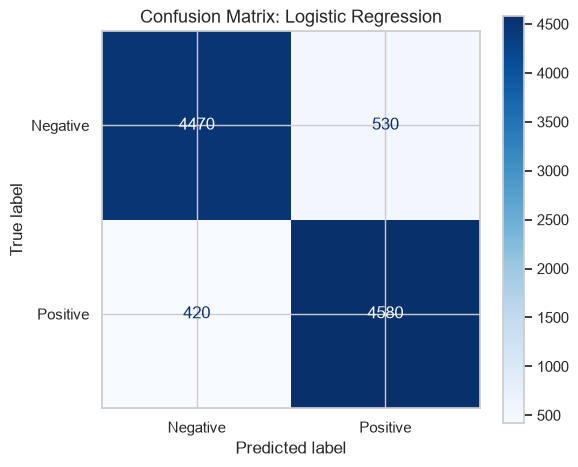

In [6]:
results = []
predictions = {}

for name, model in trained_models.items():
    y_pred = model.predict(X_test_sparse)
    predictions[name] = y_pred
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="weighted")
    results.append({"Model": name, "Accuracy": acc, "Weighted F1": f1})

results_df = pd.DataFrame(results).sort_values(by="Weighted F1", ascending=False)
print("=== Model Comparison on Test Set ===")
display(results_df)

# Select the best model
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_preds = predictions[best_model_name]

print(f"\n=== Detailed Classification Report ({best_model_name}) ===")
print(classification_report(y_test, best_preds, target_names=["Negative", "Positive"]))

# Confusion Matrix Visualization
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, best_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(cmap="Blues", ax=ax, values_format="d")
ax.set_title(f"Confusion Matrix: {best_model_name}", fontsize=13)
plt.tight_layout()
plt.show()

## Stage 6: Feature Importance & Model Interpretability
A key advantage of sparse linear models is **interpretability**. By inspecting model coefficients, we can see exactly which words or n-grams have the strongest positive and negative influence on sentiment.

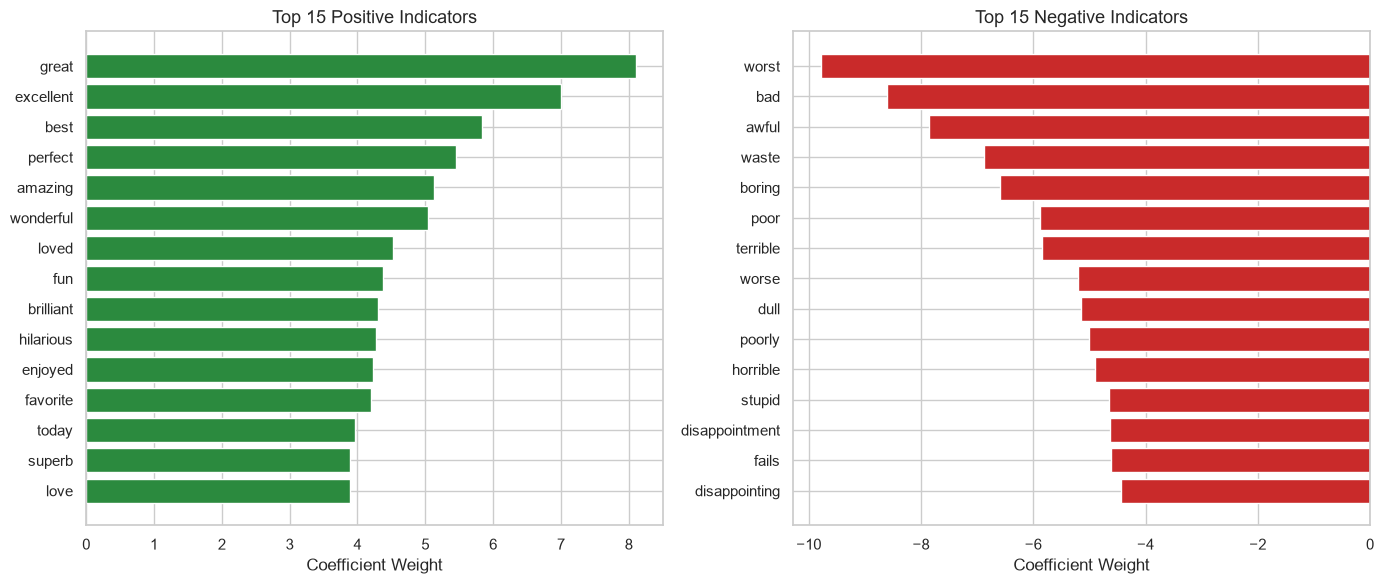

In [7]:
# Use Logistic Regression or Linear SVC for feature coefficients
lr_model = trained_models["Logistic Regression"]
feature_names = np.array(vectorizer.get_feature_names_out())
coefs = lr_model.coef_[0]

# Top 15 Positive and Negative Features
top_positive_indices = np.argsort(coefs)[-15:]
top_negative_indices = np.argsort(coefs)[:15]

top_pos_features = feature_names[top_positive_indices]
top_pos_weights = coefs[top_positive_indices]

top_neg_features = feature_names[top_negative_indices]
top_neg_weights = coefs[top_negative_indices]

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

ax1.barh(top_pos_features, top_pos_weights, color="#2b8a3e")
ax1.set_title("Top 15 Positive Indicators", fontsize=13)
ax1.set_xlabel("Coefficient Weight")

ax2.barh(top_neg_features, top_neg_weights, color="#c92a2a")
ax2.set_title("Top 15 Negative Indicators", fontsize=13)
ax2.set_xlabel("Coefficient Weight")
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

## Stage 7: Hyperparameter Tuning (Optional Optimization)
Optimize regularization parameter $C$ on the best linear model using `GridSearchCV` with cross-validation.

In [8]:
param_grid = {
    "C": [0.2, 0.5, 1.0, 2.0, 5.0]
}

print("Running GridSearchCV for Logistic Regression...")
grid_search = GridSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring="f1_weighted",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_sparse, y_train)
print(f"\nBest Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation F1-score: {grid_search.best_score_:.4f}")

tuned_model = grid_search.best_estimator_
tuned_test_acc = accuracy_score(y_test, tuned_model.predict(X_test_sparse))
print(f"Tuned Model Test Accuracy: {tuned_test_acc:.4f}")

Running GridSearchCV for Logistic Regression...
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Best Parameters: {'C': 5.0}
Best Cross-Validation F1-score: 0.8967
Tuned Model Test Accuracy: 0.9059


## Stage 8: Real-Time Inference on New Unseen Text
Define an end-to-end inference function that takes raw text, applies preprocessing, vectorizes using the saved TF-IDF vocabulary, and outputs the predicted sentiment with confidence probabilities.

In [9]:
def predict_sentiment(raw_review: str, model=best_model, vect=vectorizer):
    """Predicts sentiment for a new input string."""
    clean_input = clean_text(raw_review)
    vec_input = vect.transform([clean_input])
    pred = model.predict(vec_input)[0]
    
    sentiment = "Positive 😊" if pred == 1 else "Negative 😞"
    
    # If model supports predict_proba (e.g. Logistic Regression or Naive Bayes)
    confidence_str = ""
    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(vec_input)[0]
        confidence = probs[pred] * 100
        confidence_str = f" (Confidence: {confidence:.2f}%)"
        
    return f"{sentiment}{confidence_str}"

# Test on diverse examples
sample_reviews = [
    "An absolute masterpiece, breathtaking visuals and stellar acting!",
    "The plot was completely incoherent and a total waste of two hours.",
    "Started out promising, but the ending was deeply disappointing and dull.",
    "Not bad at all! Far better than what the negative critics claimed."
]

print("=== Live Sentiment Predictions ===\n")
for review in sample_reviews:
    print(f"Review: '{review}'")
    print(f"-> Prediction: {predict_sentiment(review, model=trained_models['Logistic Regression'])}\n")

=== Live Sentiment Predictions ===

Review: 'An absolute masterpiece, breathtaking visuals and stellar acting!'
-> Prediction: Positive 😊 (Confidence: 85.77%)

Review: 'The plot was completely incoherent and a total waste of two hours.'
-> Prediction: Negative 😞 (Confidence: 99.29%)

Review: 'Started out promising, but the ending was deeply disappointing and dull.'
-> Prediction: Negative 😞 (Confidence: 98.51%)

Review: 'Not bad at all! Far better than what the negative critics claimed.'
-> Prediction: Negative 😞 (Confidence: 81.15%)



## Stage 9: Model & Vectorizer Persistence
Save the fitted TF-IDF vectorizer and trained model to disk so they can be loaded directly for deployment or API serving without retraining.

In [ ]:
models_dir = os.path.join("..", "models")
os.makedirs(models_dir, exist_ok=True)

vectorizer_path = os.path.join(models_dir, "tfidf_vectorizer.joblib")
model_path = os.path.join(models_dir, "sentiment_linear_model.joblib")

joblib.dump(vectorizer, vectorizer_path)
joblib.dump(best_model, model_path)

print(f"Artifacts saved successfully:")
print(f" - Vectorizer: {vectorizer_path} ({os.path.getsize(vectorizer_path) / 1024:.1f} KB)")
print(f" - Model:      {model_path} ({os.path.getsize(model_path) / 1024:.1f} KB)")